# CITS5508 - Assignment 1 2026

## Part 1: Softmax Regression

1. Load the MNIST dataset from OpenML using scikit-learn

In [8]:
from sklearn.datasets import fetch_openml
import numpy as np
import matplotlib.pyplot as plt

In [9]:
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)

2. Display some examples from the dataset. Describe what features and labels represent.

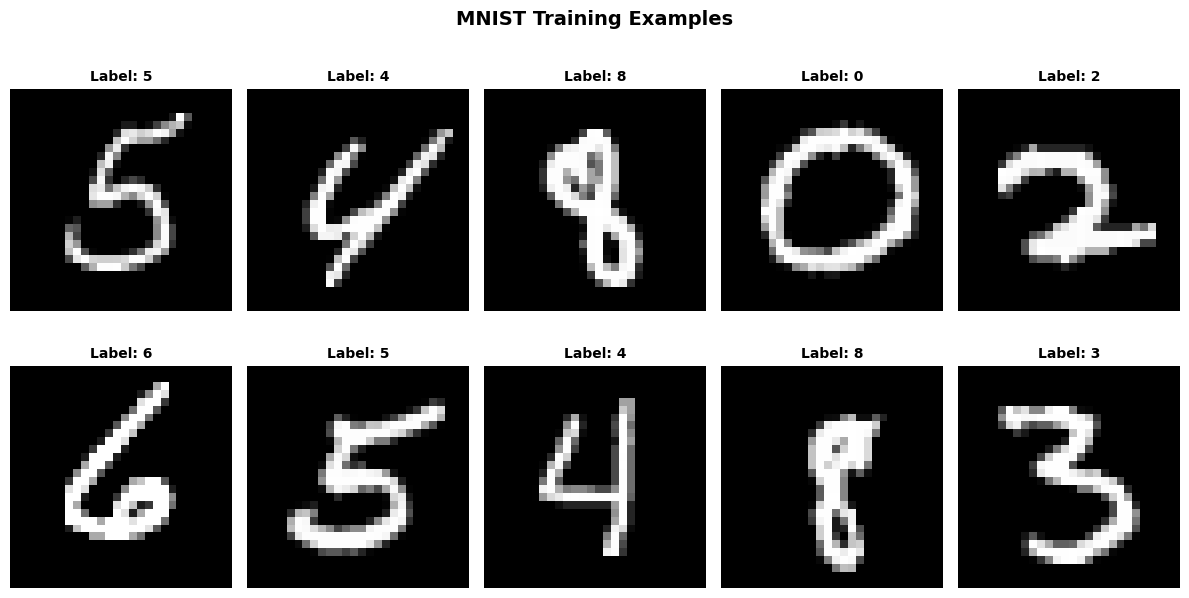

In [ ]:
# display some examples from the dataset
plt.figure(figsize=(12, 6.5))
plt.suptitle("MNIST Dataset Examples", fontsize=14, fontweight="bold")
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {int(y[i])}", fontsize=10, fontweight="bold")
    plt.axis("off")

plt.tight_layout()
plt.show()

The MNIST dataset consists of 70,000 grayscale images where each each represents a single handwritten digit. The images have a fixed resolution of 28x28 pixels and each image contains 784 numerical features. Thus, the features are the pixel intensity values (out of 784) and the labels are which number from 0 to 9 each image corresponds to.

3. Split the dataset into a training, validation, and test set. You should use 70% of the data for training, 15% for validation, and 15% for testing.

In [ ]:
from sklearn.model_selection import train_test_split

# split the data into training and temp sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# split temp into validation and testing sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# normalize the data
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (49000, 784) (49000,)
Validation shape: (10500, 784) (10500,)
Test shape: (10500, 784) (10500,)


(a) Display the class distribution in the training, validation, and test sets

In [25]:
import numpy as np
import pandas as pd

def show_class_distribution(labels, name):
    classes, counts = np.unique(labels, return_counts=True)
    proportions = counts / counts.sum()

    df = pd.DataFrame({
        "Class": classes,
        "Count": counts,
        "Proportion": proportions
    })

    print(f"\n{name} class distribution:")
    display(df)

show_class_distribution(y_train, "Training")
show_class_distribution(y_val, "Validation")
show_class_distribution(y_test, "Test")


Training class distribution:


,Class,Count,Proportion
0,0,4845,0.098878
1,1,5513,0.112510
2,2,4857,0.099122
3,3,4965,0.101327
4,4,4888,0.099755
5,5,4398,0.089755
6,6,4788,0.097714
7,7,5045,0.102959
8,8,4833,0.098633
9,9,4868,0.099347



Validation class distribution:


,Class,Count,Proportion
0,0,1022,0.097333
1,1,1138,0.108381
2,2,1084,0.103238
3,3,1046,0.099619
4,4,963,0.091714
5,5,953,0.090762
6,6,1085,0.103333
7,7,1162,0.110667
8,8,999,0.095143
9,9,1048,0.099810



Test class distribution:


,Class,Count,Proportion
0,0,1036,0.098667
1,1,1226,0.116762
2,2,1049,0.099905
3,3,1130,0.107619
4,4,973,0.092667
5,5,962,0.091619
6,6,1003,0.095524
7,7,1086,0.103429
8,8,993,0.094571
9,9,1042,0.099238


(b) Do you need to stratify your split? Why or why not?

Stratification is not necessary for this dataset, but it is a good practice to uphold. 